In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from cvxopt import matrix, solvers
import math
import matplotlib.pyplot as plt
from utils import *
from class_utils import *
from scipy.spatial.distance import cdist 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix
from collections import defaultdict
from random import sample

In [2]:
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF

In [3]:
import ot
import ot.plot

In [4]:
df_spectra = pd.read_csv('spectral_data_all.csv')
df_spectra.drop(columns=['Unnamed: 0'], inplace=True)

In [120]:
df_spectra_flopp = df_spectra.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
df_spectra_flopp = df_spectra_flopp.query('polymer != "Ethylene Acrylic Acid" and polymer != "Polyethylene Adipate" and polymer != "Silicone Rubber"').reset_index(drop=True)


In [121]:
df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_spectra_flopp

,wavelength,intensity,file_name,polymer,data_source,type_sprectra
0,674.9918,-0.070660,PEVA 11. Purple Fiber.CSV,Polyethylene Vinyl Acetate,flopp,FTIR
1,676.9203,0.360568,PEVA 11. Purple Fiber.CSV,Polyethylene Vinyl Acetate,flopp,FTIR
2,678.8489,0.622882,PEVA 11. Purple Fiber.CSV,Polyethylene Vinyl Acetate,flopp,FTIR
3,680.7775,0.498112,PEVA 11. Purple Fiber.CSV,Polyethylene Vinyl Acetate,flopp,FTIR
4,682.7060,0.218716,PEVA 11. Purple Fiber.CSV,Polyethylene Vinyl Acetate,flopp,FTIR
...,...,...,...,...,...,...
652045,3992.0940,0.490823,PC 1. White Fragment.CSV,Polycarbonate,flopp_e,FTIR
652046,3994.0230,0.520239,PC 1. White Fragment.CSV,Polycarbonate,flopp_e,FTIR
652047,3995.9510,0.519827,PC 1. White Fragment.CSV,Polycarbonate,flopp_e,FTIR
652048,3997.8800,0.530164,PC 1. White Fragment.CSV,Polycarbonate,flopp_e,FTIR


In [122]:
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[146:-1]
df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
#df_flopp_pivot = df_flopp_pivot.drop(df_flopp_pivot.columns[range(3,146)], 
#                    axis=1).iloc[:,:-1]

In [123]:
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()
df_flopp_pivot

,file_name,polymer,data_source,wl_67499,wl_67692,wl_67885,wl_68078,wl_68271,wl_68463,wl_68656,...,wl_398245,wl_398438,wl_398631,wl_398824,wl_399017,wl_399209,wl_399402,wl_399595,wl_399788,wl_399981
0,ABS 1. Black Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp_e,-1.652339,-1.716827,-1.864428,-1.967062,-2.049846,-2.187845,-2.477509,...,0.478590,0.474398,0.473947,0.481465,0.479542,0.479669,0.483015,0.476869,0.475167,0.482083
1,ABS 1. Orange LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.558419,-2.617344,-2.647565,-2.732447,-2.850790,-2.988317,-3.196264,...,0.637547,0.634108,0.648501,0.656325,0.655386,0.664971,0.665558,0.651044,0.645997,0.654486
2,ABS 10. Brown LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.265023,-2.309608,-2.374530,-2.446580,-2.540923,-2.695691,-2.891053,...,0.832796,0.829453,0.840934,0.849702,0.846336,0.842218,0.841419,0.842121,0.844761,0.844858
3,ABS 11. Black LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.061761,-2.108204,-2.142853,-2.220130,-2.299527,-2.437295,-2.648397,...,0.696705,0.688823,0.696865,0.706376,0.712737,0.715482,0.715432,0.705735,0.699177,0.700378
4,ABS 12. White LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-4.333531,-4.334141,-4.328848,-4.340096,-4.405816,-4.480118,-4.589519,...,0.439976,0.435928,0.447634,0.458499,0.456927,0.451888,0.451876,0.449256,0.447064,0.447839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,R 4. Black Bridgestone Tire Fragment.CSV,Rubber,flopp,-1.059914,-1.094170,-1.130550,-1.159701,-1.189228,-1.218819,-1.259491,...,0.668248,0.669790,0.673395,0.672920,0.673833,0.675912,0.672733,0.670605,0.673714,0.673574
374,R 5. Black Michelin Tire Fragment.CSV,Rubber,flopp,-0.911333,-0.947815,-0.963645,-0.973925,-1.003195,-1.033317,-1.063904,...,0.531372,0.531329,0.529879,0.528860,0.529708,0.530439,0.531653,0.532614,0.533305,0.532427
375,R 6. Black Bike Tire Fragment.CSV,Rubber,flopp,-0.516341,-0.546198,-0.556689,-0.539175,-0.577721,-0.618201,-0.678861,...,0.379056,0.370742,0.381748,0.391027,0.390442,0.384034,0.387614,0.391387,0.387133,0.387726
376,R 8. White Bike Tire Fragment.CSV,Rubber,flopp,-2.848426,-2.819902,-2.796277,-2.773726,-2.762003,-2.737744,-2.718932,...,0.609851,0.608619,0.608971,0.607739,0.606495,0.605651,0.604783,0.603891,0.603293,0.601322


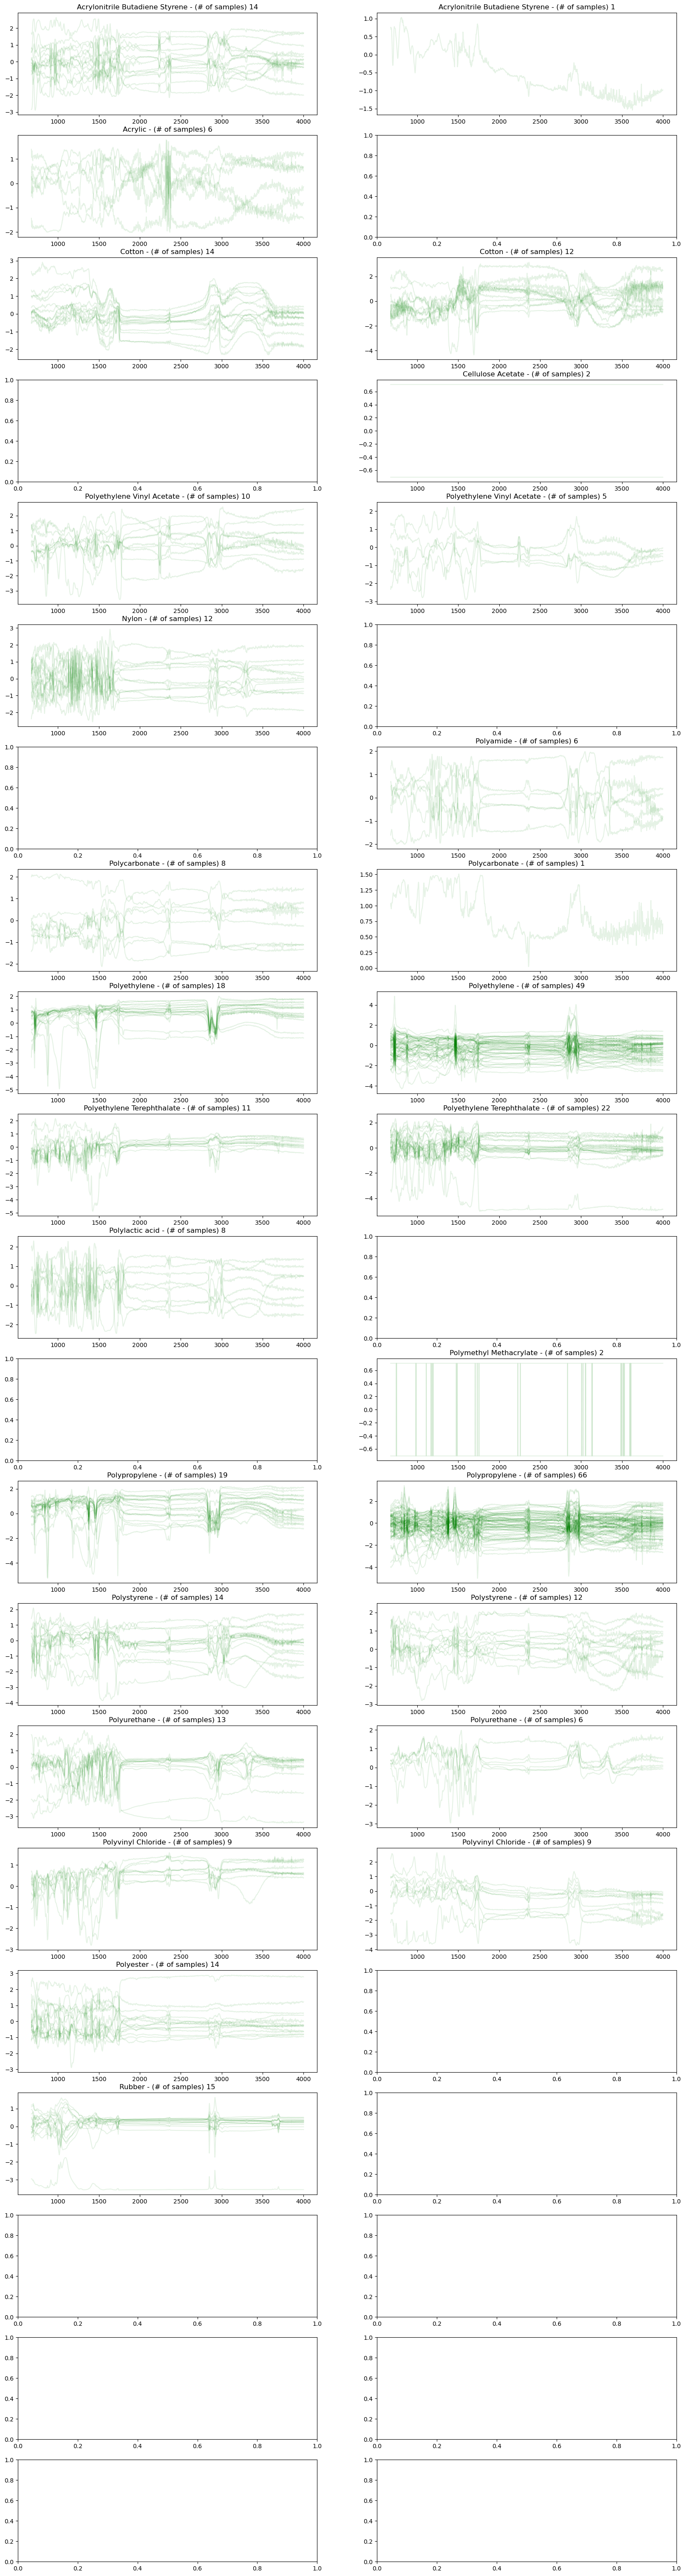

In [105]:
fig, ax = plt.subplots(nrows=21, ncols=2)
fig.set_figheight(40)
fig.set_figwidth(20)
for j, ds in enumerate(['flopp', 'flopp_e']):
    for i, p in enumerate(polymer_list): #polymer_list
        
        df_fltered = df_spectra_flopp.query('polymer == @p and data_source == @ds')
        df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
        file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
        n_files = len(file_name_list)

        for fn in file_name_list:
            _ = ax[i, j].plot(df_fltered.query('file_name == @fn')['wavelength'],
                              df_fltered.query('file_name == @fn')['intensity'],
                              alpha=0.1,
                              color='g')
            _ = ax[i, j].title.set_text(p + ' - (# of samples) ' + str(n_files))
    
            #_ = ax[i, j].plot()
            #_ = ax[i, j].plot()
            #_ = ax[i, j].legend()
            #
fig.subplots_adjust(left=None, 
                            bottom=0, 
                            right=None, 
                            top=1.5, 
                            wspace=None, 
                            hspace=None)
#plt.savefig('/Users/eochoa/Documents/Research_Abuj/M4AM/spectral_libraries/spectra.pdf')

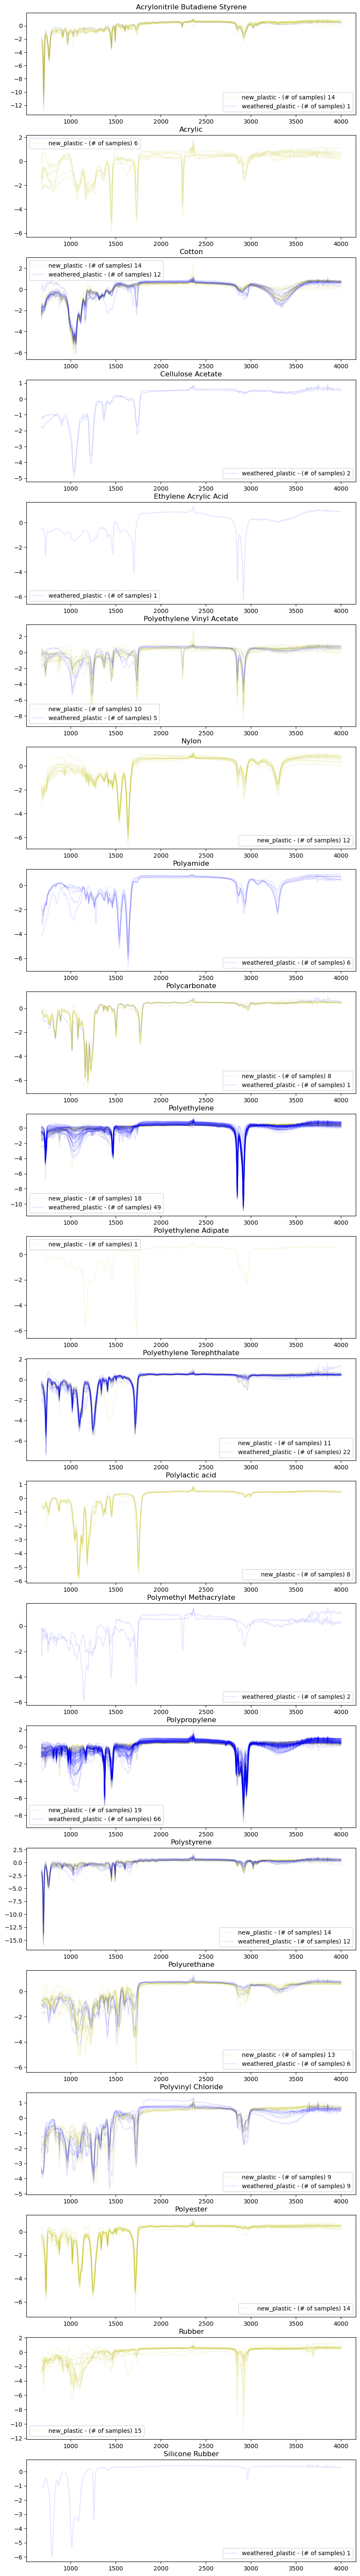

In [185]:
fig, ax = plt.subplots(nrows=21)
fig.set_figheight(40)
fig.set_figwidth(10)
for j, ds in enumerate(['flopp', 'flopp_e']):
    for i, p in enumerate(polymer_list):
        
        df_fltered = df_spectra_flopp.query('polymer == @p and data_source == @ds')
        df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
        file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
        n_files = len(file_name_list)
        
        if ds == 'flopp':
            color = 'y'
            label = 'new_plastic'
        else:
            color = 'b'
            label = 'weathered_plastic'
            

        for fn in file_name_list:

            if fn == file_name_list[0]:
                _ = ax[i].plot(df_fltered.query('file_name == @fn')['wavelength'],
                               df_fltered.query('file_name == @fn')['intensity'],
                               alpha=0.1,
                               color=color,
                               label=label + ' - (# of samples) ' + str(n_files))
                _ = ax[i].title.set_text(p)
                _ = ax[i].legend()
            else:
                _ = ax[i].plot(df_fltered.query('file_name == @fn')['wavelength'],
                               df_fltered.query('file_name == @fn')['intensity'],
                               alpha=0.1,
                               color=color)
                _ = ax[i].title.set_text(p)
            #_ = ax[i, j].plot()
            #_ = ax[i, j].plot()
            #_ = ax[i, j].legend()
            #
        
fig.subplots_adjust(left=None, 
                            bottom=0, 
                            right=None, 
                            top=1.5, 
                            wspace=None, 
                            hspace=None)

In [124]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:]
X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:]
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1]
y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1]

In [125]:
# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
n, p = x_train.shape

# Logistic Regresion

In [126]:
clf = LogisticRegression(random_state=52, multi_class='multinomial').fit(X_train, y_train) # 80 / 20
clf.score(X_test, y_test)

0.7927461139896373

best C: 7.00


(7.0, 0.9473856209150326)

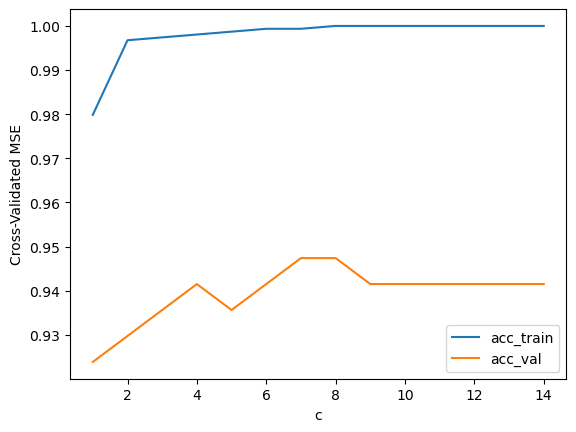

In [71]:
clf = model_logReg()
clf.train_data(x_train, y_train_)
clf.cv(folds, list(range(1, 15)), plot_=True)

In [109]:
clf.score(X_test, y_test)

0.07253886010362694

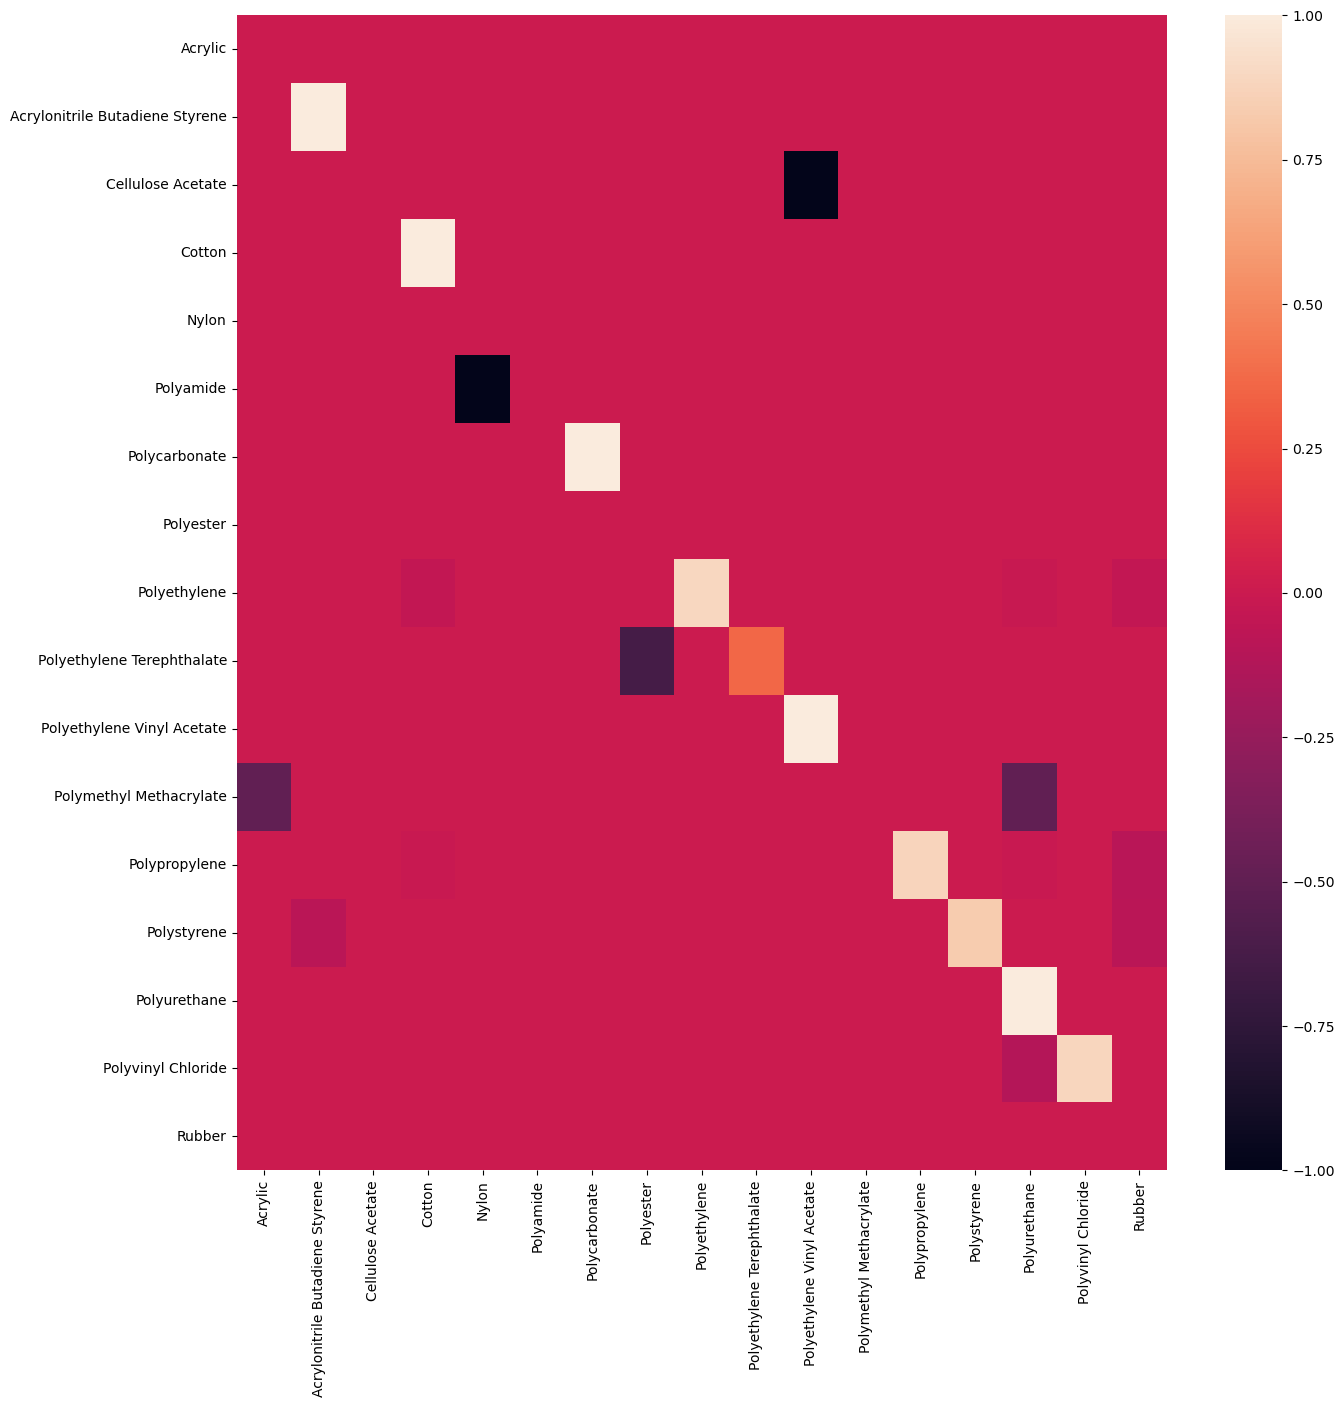

In [129]:
y_test_hat = clf.predict(X_test)
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

# Random Forest

best max_depth: 10.00
best n_estimators: 60.00


(10.0, 60, 0.8830065359477125)

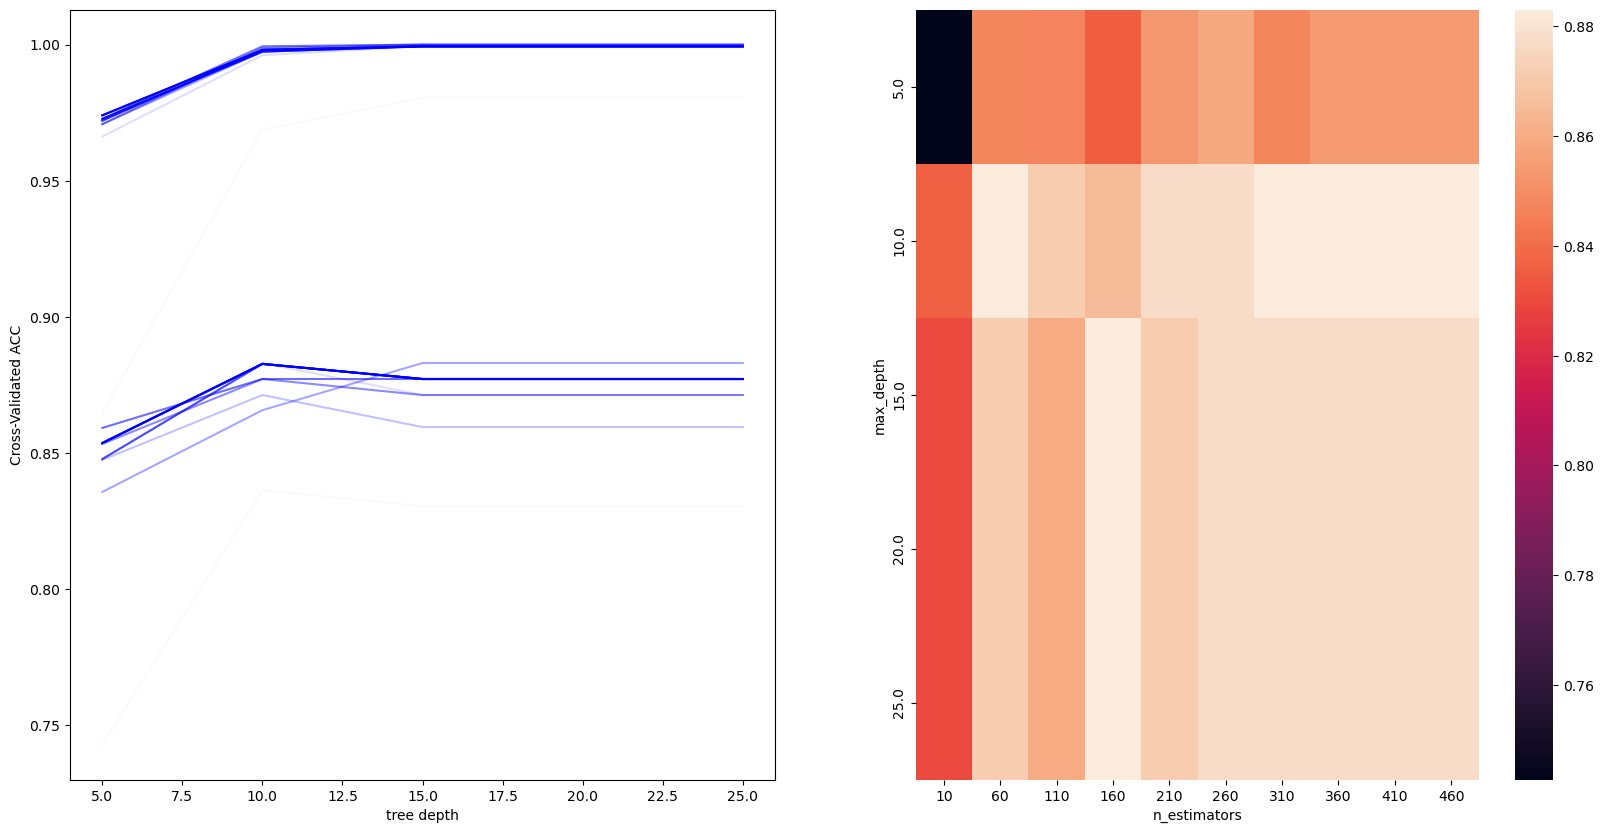

In [73]:
rf = model_randF()
rf.train_data(x_train, y_train_)
rf.fit()
#clf.score(X_test, y_test)
rf.cv(folds, (5, 10, 20, 15, 20, 25, None), 
       np.arange(10, 500, 50), plot_=True)

In [74]:
rf.score(X_test, y_test)

0.6820512820512821

# KNN

best n_neighbors: 1.00


(1.0, 0.9356209150326797)

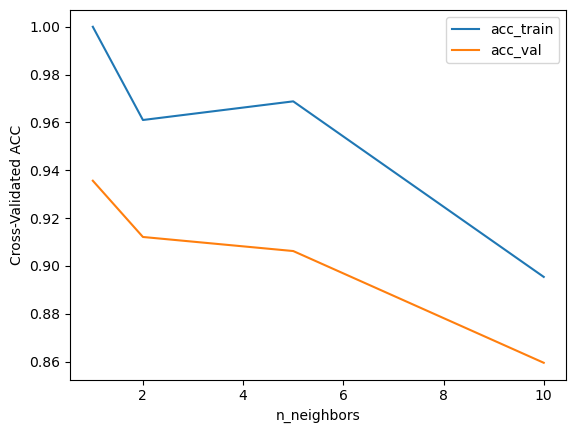

In [75]:
knn = model_knn()
knn.train_data(x_train, y_train_)
knn.fit()
#clf.score(X_test, y_test)
knn.cv(folds, (1, 2, 5, 10), plot_=True)

In [76]:
knn.score(X_test, y_test)

0.717948717948718

# SVM

In [82]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [86]:
#svm = make_pipeline(StandardScaler(), SVC(gamma='auto', probability=True))
svm = SVC(gamma='auto', probability=True)
svm.fit(X_train, y_train)
svm.score(X_test, y_test)

0.7076923076923077

## Kernel Mean Matching

In [1051]:
# an implementation of Kernel Mean Matchin
# referenres:
#  1. Gretton, Arthur, et al. "Covariate shift by kernel mean matching." Dataset shift in machine learning 3.4 (2009): 5.
#  2. Huang, Jiayuan, et al. "Correcting sample selection bias by unlabeled data." Advances in neural information processing systems. 2006.
def kernel_mean_matching(X, Z, kern='lin', B=1.0, eps=None):
    nx = X.shape[0]
    nz = Z.shape[0]
    if eps == None:
        eps = B/math.sqrt(nz)
    if kern == 'lin':
        K = np.dot(Z, Z.T)
        kappa = np.sum(np.dot(Z, X.T)*float(nz)/float(nx),axis=1)
    elif kern == 'rbf':
        K = compute_rbf(Z,Z)
        kappa = np.sum(compute_rbf(Z,X),axis=1)*float(nz)/float(nx)
    else:
        raise ValueError('unknown kernel')
        
    K = matrix(K)
    kappa = matrix(kappa)
    G = matrix(np.r_[np.ones((1,nz)), -np.ones((1,nz)), np.eye(nz), -np.eye(nz)])
    h = matrix(np.r_[nz*(1+eps), nz*(eps-1), B*np.ones((nz,)), np.zeros((nz,))])
    
    sol = solvers.qp(K, -kappa, G, h)
    coef = np.array(sol['x'])
    return coef

def compute_rbf(Z, sigma=2):
    M = np.dot(Z, Z.T)
    D = np.diag(np.diag(M))
    K = np.exp((-np.dot(np.ones_like(M), D) + np.dot(D, np.ones_like(M)) - 2 * M) / 2)
    return K

In [1052]:
Z = np.matrix(X_train)
X = np.matrix(X_test)

In [1207]:
#beta_rbf = kernel_mean_matching(X, Z, kern='rbf', B=1.0, eps=None)
#beta_rbf = beta_rbf.reshape((171,))

In [1054]:
beta_lin = kernel_mean_matching(X, Z, kern='lin', B=1.0, eps=None)
beta_lin = beta_lin.reshape((171,))

     pcost       dcost       gap    pres   dres
 0: -2.4043e+06 -2.4053e+06  5e+04  8e-01  3e-16
 1: -2.4034e+06 -2.4038e+06  1e+04  2e-01  3e-16
 2: -2.4028e+06 -2.4016e+06  1e+04  1e-01  2e-16
 3: -2.4019e+06 -2.3978e+06  9e+03  1e-01  2e-16
 4: -2.4002e+06 -2.3930e+06  8e+03  7e-02  2e-16
 5: -2.3987e+06 -2.3890e+06  9e+03  6e-02  2e-16
 6: -2.3962e+06 -2.3835e+06  1e+04  5e-02  2e-16
 7: -2.3930e+06 -2.3780e+06  1e+04  4e-02  2e-16
 8: -2.3898e+06 -2.3741e+06  1e+04  3e-02  2e-16
 9: -2.3877e+06 -2.3723e+06  1e+04  3e-02  2e-16
10: -2.3853e+06 -2.3702e+06  1e+04  3e-02  2e-16
11: -2.3824e+06 -2.3672e+06  1e+04  2e-02  2e-16
12: -2.3799e+06 -2.3641e+06  1e+04  2e-02  2e-16
13: -2.3766e+06 -2.3617e+06  1e+04  2e-02  2e-16
14: -2.3729e+06 -2.3591e+06  1e+04  1e-02  2e-16
15: -2.3689e+06 -2.3577e+06  1e+04  1e-02  2e-16
16: -2.3641e+06 -2.3562e+06  1e+04  7e-03  2e-16
17: -2.3572e+06 -2.3542e+06  7e+03  3e-03  2e-16
18: -2.3556e+06 -2.3540e+06  7e+03  2e-03  2e-16
19: -2.3520e+06 -2.35

In [1055]:
clf = LogisticRegression().fit(X_train, y_train, sample_weight=beta_rbf)
clf.score(X_test, y_test)

0.7794871794871795

In [1056]:
clf = LogisticRegression().fit(X_train, y_train, sample_weight=beta_lin)
clf.score(X_test, y_test)

0.7692307692307693

## Optimal Transport

In [1057]:
y_train_ext = pd.Series()
X_test_ext = pd.DataFrame()

y_test_ext = pd.DataFrame()
#X_test_ext = pd.DataFrame()

for j in range(X_test.shape[0]):
    y_train_ext = pd.concat([y_train_ext, y_train])
    #y_test_ext = pd.concat([y_test_ext, y_test])
    #X_test_ext = pd.concat([X_test_ext, X_test])
    X_test_ext = pd.concat([X_test_ext] + [X_test.iloc[j:(j + 1),:]] * 171)

In [1058]:
n = X_train.shape[0]
ntest = X_test.shape[0]
wa=np.ones((n,))/n
wb=np.ones((ntest,))/ntest
C0 = cdist(X_train,X_test,metric='sqeuclidean')
alpha = .01
Chinge = np.zeros_like(C0)
C = alpha*C0+Chinge
G = ot.sinkhorn(wa,wb,C,1)
beta = G.reshape((33345,), order='F')

In [1059]:
clf = LogisticRegression().fit(X_test_ext, y_train_ext, sample_weight=beta) # 80 / 20
print(clf.score(X_test, y_test))

0.517948717948718


In [1060]:
def loss_hinge(Y,F):
    res=np.zeros((Y.shape[0],F.shape[0]))
    for i in range(Y.shape[1]):
        res+=np.maximum(0,1-Y[:,i].reshape((Y.shape[0],1))*F[:,i].reshape((1,F.shape[0])))**2
    return res

In [1061]:
def get_label_matrix(y, vals):
    #vals=np.unique(y)
   
    # class matrices for source
    Y=np.zeros((len(y),len(vals)))
    Yb=np.zeros((len(y),len(vals)))
    for i,val in enumerate(vals):
        Y[:,i]=2*((y==val)-.5)
        Yb[:,i]=(y==val)
    return Y,Yb

In [1062]:
Y_train = get_label_matrix(y_train, np.unique(y_train))[0]
Y_test = get_label_matrix(clf.predict(X_test), np.unique(y_train))[0]

<AxesSubplot: >

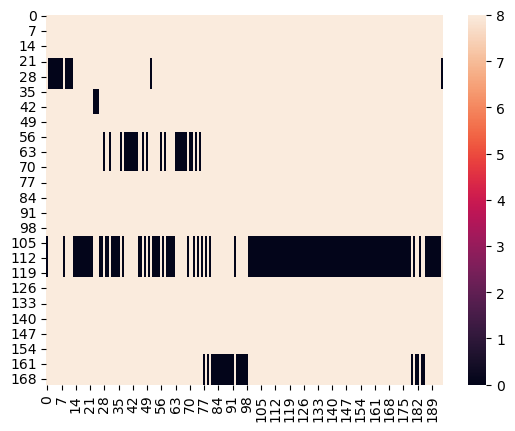

In [1063]:
sns.heatmap(loss_hinge(Y_train, Y_test))

In [1064]:
G_prime = np.ones_like(G)
for i, y1 in enumerate(y_train):
    for j, y2 in enumerate(y_test):
        G_prime[i, j] = (y1 == y2) * 1

G_prime

array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

<AxesSubplot: >

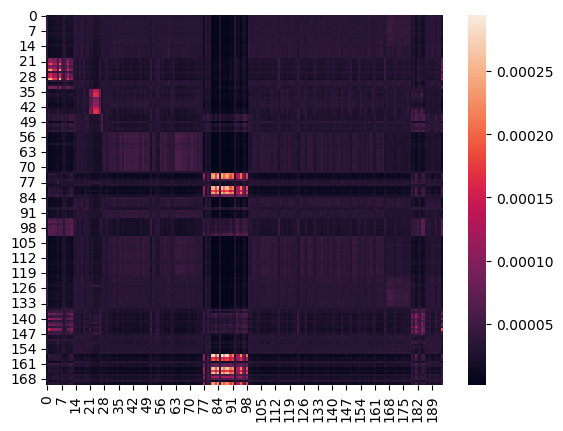

In [1065]:
sns.heatmap(G)

<AxesSubplot: >

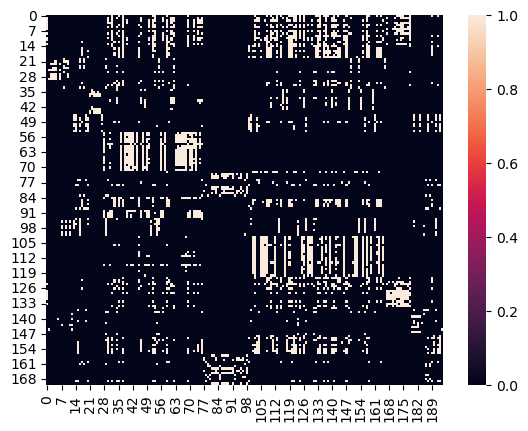

In [1067]:
alpha = .7
C = alpha*C0+Chinge

G = ot.sinkhorn(wa,wb,C,1)
sns.heatmap((G > np.quantile(G, 0.9)))

<AxesSubplot: >

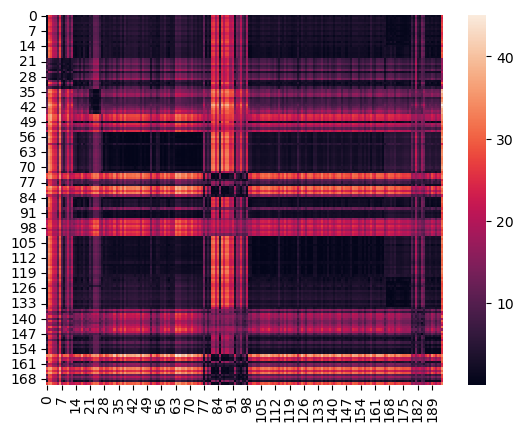

In [1068]:
sns.heatmap(0.1*C0)

<AxesSubplot: >

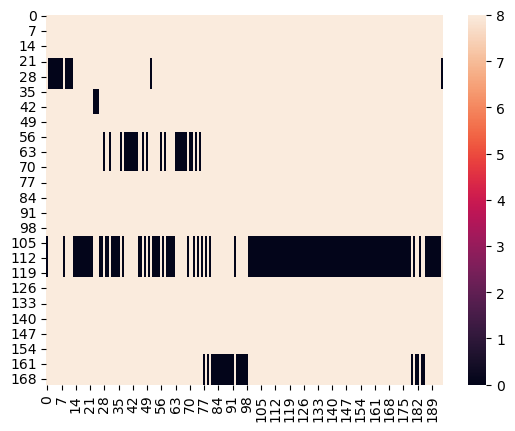

In [1069]:
Chinge = loss_hinge(Y_train, Y_test)
sns.heatmap(Chinge)

<AxesSubplot: >

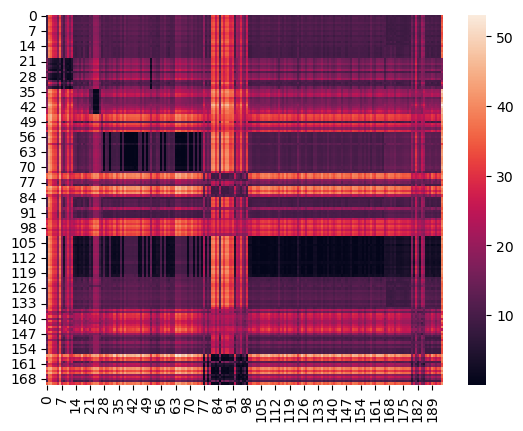

In [1203]:
sns.heatmap(.1*C0 + Chinge)

<AxesSubplot: >

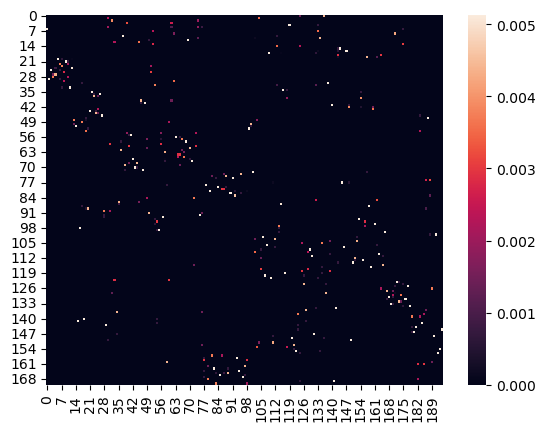

In [1204]:
C = .1*C0 + Chinge
G = ot.emd(wa,wb,C)
sns.heatmap(G)

<AxesSubplot: >

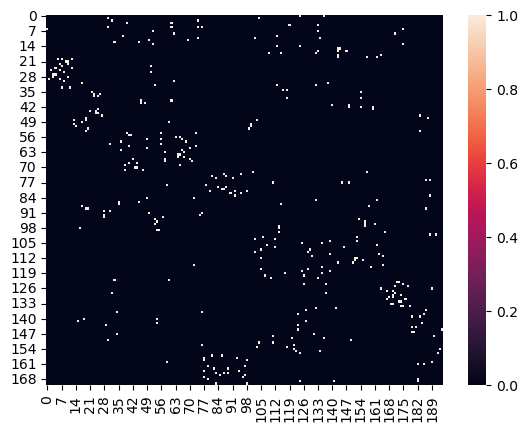

In [1205]:
sns.heatmap((G > np.quantile(G, 0.9)))

In [1074]:
clf = LogisticRegression().fit(X_train, y_train)
clf.score(X_test, y_test)

0.7794871794871795

In [1075]:
for q in np.linspace(0.1, 0.9, 10):
    beta = G.reshape((33345,), order='F')
    #q = 0.75
    clf = LogisticRegression().fit(X_test_ext.iloc[beta > np.quantile(beta, q),:], 
                                    np.array(y_train_ext)[beta > np.quantile(beta, q)], 
                                       sample_weight=beta[beta > np.quantile(beta, q)]) # 80 / 20
    print(clf.score(X_test, y_test))

0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025
0.7025641025641025


In [1076]:
beta = G_prime.reshape((33345,), order='F')
q = 0
clf = LogisticRegression().fit(X_test_ext.iloc[beta > np.quantile(beta, q),:], 
                               np.array(y_train_ext)[beta > np.quantile(beta, q)], 
                               sample_weight=beta[beta > np.quantile(beta, q)]) # 80 / 20
print(clf.score(X_test, y_test))

0.9384615384615385


In [876]:
alpha = 0.1

for k in range(1):
    
    #score_test_all = clf.decision_function(X_test)
    #for i, y in enumerate(y_train):
    #    for j in range(X_test.shape[0]):
    #        score_test = score_test_all[j,:]
    #        y_true = (y == clf.classes_)
    #        Chinge[i, j] = max(0, 1 + score_test.max() - score_test[y_true])[0]
    
    Y_test = get_label_matrix(clf.predict(X_test), np.unique(y_train))[0]
    Chinge = loss_hinge(Y_train, Y_test)
    C = alpha*C0+Chinge
    #G = ot.sinkhorn(wa,wb,C,1)
    G = ot.emd(wa,wb,C)
    beta = G.reshape((33345,), order='F')
    
    #clf = LogisticRegression().fit(X_test_ext.iloc[beta > np.quantile(beta, 0.9),:], 
    #                               np.array(y_train_ext)[beta > np.quantile(beta, 0.9)], 
    #                               sample_weight=beta[beta > np.quantile(beta, 0.9)]) # 80 / 20
    clf.fit(X_test_ext, y_train_ext, sample_weight=beta)
                                   
    print(clf.score(X_test, y_test))

0.7589743589743589


In [875]:
#alpha = 0.1

for alpha in np.linspace(0.001, 0.01, 1):
    
    #score_test_all = clf.decision_function(X_test)
    #for i, y in enumerate(y_train):
    #    for j in range(X_test.shape[0]):
    #        score_test = score_test_all[j,:]
    #        y_true = (y == clf.classes_)
    #        Chinge[i, j] = max(0, 1 + score_test.max() - score_test[y_true])[0]
    
    Y_test = get_label_matrix(clf.predict(X_test), np.unique(y_train))[0]
    Chinge = loss_hinge(Y_train, Y_test)
    C = alpha*C0+Chinge
    #G = ot.sinkhorn(wa,wb,C,1)
    G = ot.emd(wa,wb,C)
    beta = G.reshape((33345,), order='F')
    
    #clf = LogisticRegression().fit(X_test_ext.iloc[beta > np.quantile(beta, 0.9),:], 
    #                               np.array(y_train_ext)[beta > np.quantile(beta, 0.9)], 
    #                               sample_weight=beta[beta > np.quantile(beta, 0.9)]) # 80 / 20
    clf.fit(X_test_ext, y_train_ext, sample_weight=beta)
                                   
    print(clf.score(X_test, y_test))

0.7692307692307693


<AxesSubplot: >

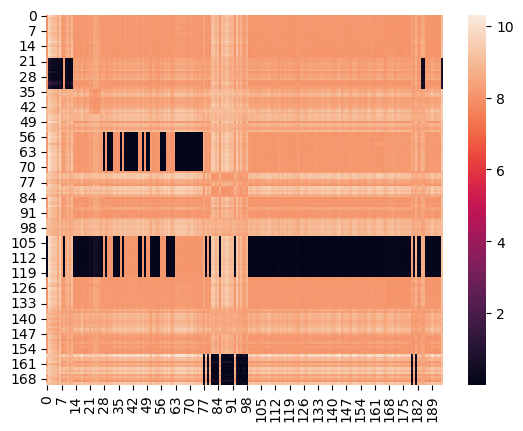

In [645]:
sns.heatmap(0.05*C0 + Chinge)

<AxesSubplot: >

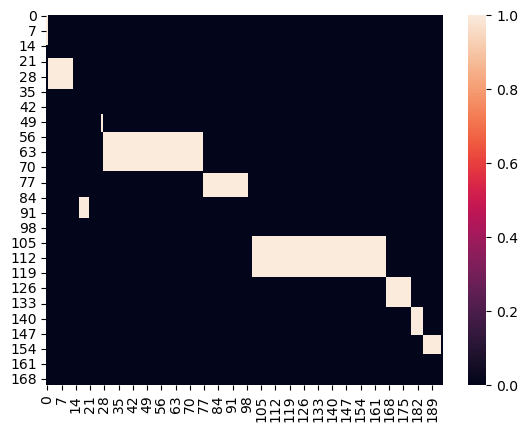

In [1201]:
sns.heatmap(G_prime)

In [1202]:
X_test_1, X_test_2, y_test_1, y_test_2 = train_test_split(
    X_test, y_test, test_size=0.33, random_state=42)

In [1297]:
p_list = list()
transp_Xs_emd = list()#pd.DataFrame()
transp_mappings = list()#pd.DataFrame()
for p in np.unique(y_train):
    if sum(y_test_1 == p) * sum(y_test_2 == p) * sum(y_train == p) > 0:
        Xs=np.array(X_test_1[y_test_1 == p])
        Xt=np.array(X_train[y_train == p])
        ot_emd = ot.da.EMDTransport()
        ot_emd.fit(Xs=Xs, Xt=Xt)
        
        p_list.append(y_test_2[y_test_2 == p])
        transp_Xs_emd.append(pd.DataFrame(ot_emd.transform(Xs=np.array(X_test_2[y_test_2 == p]))))
        transp_mappings.append(ot_emd.transform)

transp_Xs_emd = pd.concat(transp_Xs_emd)
transp_Xs_emd.columns = X_test_1.columns
transp_Xs_emd = transp_Xs_emd.reset_index(drop=True)
transp_Xs_emd
transp_ys = pd.concat(p_list).reset_index(drop=True)
transp_ys

0                 Cotton
1                 Cotton
2                 Cotton
3           Polyethylene
4           Polyethylene
             ...        
58           Polystyrene
59           Polystyrene
60          Polyurethane
61    Polyvinyl Chloride
62    Polyvinyl Chloride
Name: polymer, Length: 63, dtype: object

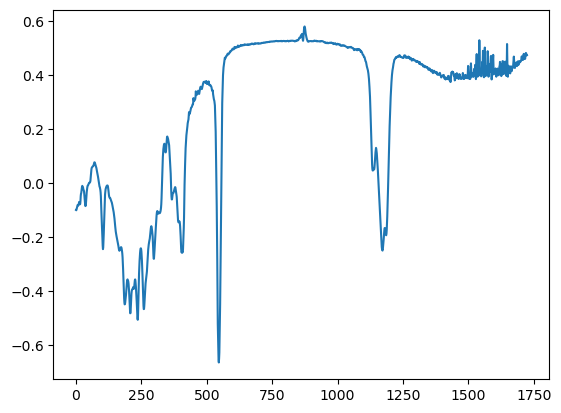

In [1360]:
plt.plot(np.array(X_test_2[y_test_2 == p])[1])

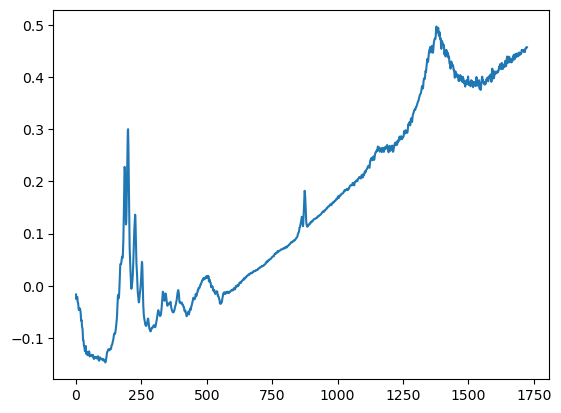

In [1331]:
plt.plot(transp_mappings[0](np.linspace(-.2, 0.5, 1725).reshape((1,1725))).flatten())
#transp_mappings[0](np.array(X_test_2[y_test_2 == p]))

In [1396]:
bar_cent = ot.bregman.convolutional_barycenter2d(np.array(X_train[y_train == p]).reshape((9,1,1725)), 
                                      0.1, 
                                      np.ones(9) / 9)

In [1438]:
M = ot.dist(np.transpose(bar_cent), np.transpose(np.array(X_test_2[y_test_2 == p])[1:2]), 'euclidean')
M /= M.max() * 0.1
ot.emd2([],[],M) 

0.4476692816277361

In [1436]:
p

'Polyvinyl Chloride'

In [1439]:
bar_cent_list = []
for p in np.unique(y_train):
    
    n_p = sum(y_train == p)
    bar_cent = ot.bregman.convolutional_barycenter2d(np.array(X_train[y_train == p]).reshape((n_p,1,1725)), 
                                      0.1, 
                                      np.ones(n_p) / n_p)
    bar_cent_list.append(bar_cent)
    
    M = ot.dist(np.transpose(bar_cent), np.transpose(np.array(X_test_2[y_test_2 == 'Polyvinyl Chloride'])[0:1]), 'euclidean')
    M /= M.max() * 0.1
    print(ot.emd2([],[],M) )
    

0.48668994629979095


KeyboardInterrupt: 

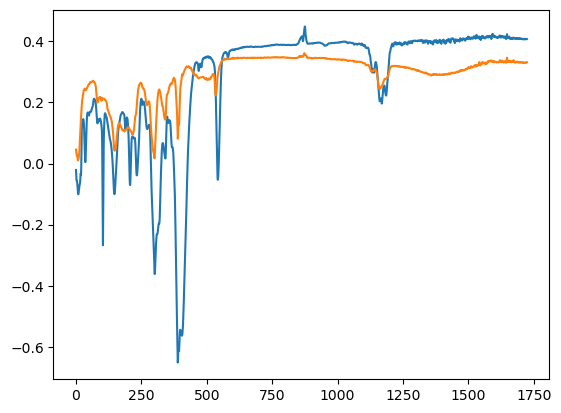

In [1512]:
for 

plt.plot(np.array(X_train[y_train == 'Polyvinyl Chloride'])[0])
plt.plot(np.array(X_test_2[y_test_2 == 'Polyvinyl Chloride'])[0])

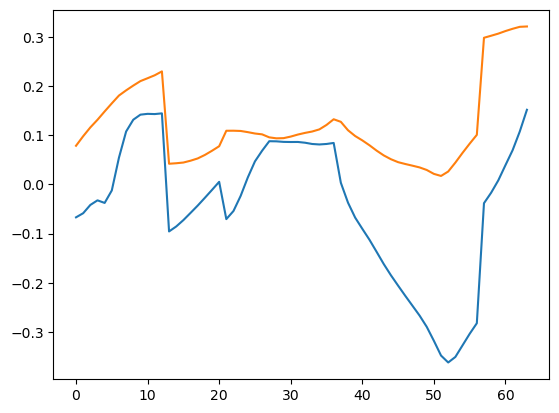

In [1499]:
plt.plot(np.array(X_train.loc[y_train == 'Polyvinyl Chloride',
                         (clf.coef_ > 0)[12,:]])[0])
plt.plot(np.array(X_test_2.loc[y_test_2 == 'Polyvinyl Chloride',
                          (clf.coef_ > 0)[12,:]])[0])

In [1503]:
np.power(np.array(X_train.loc[y_train == 'Polyvinyl Chloride',
                         (clf.coef_ > 0)[12,:]])[0] - np.array(X_test_2.loc[y_test_2 == 'Polyvinyl Chloride',
                          (clf.coef_ > 0)[12,:]])[0], 2).mean()

0.04065367843839269

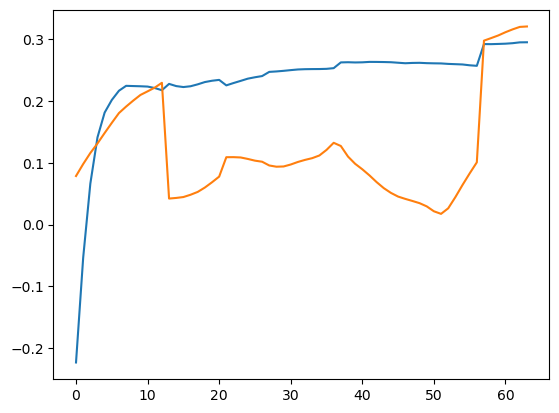

In [1500]:
plt.plot(np.array(X_train.loc[y_train == 'Polystyrene',
                         (clf.coef_ > 0)[12,:]])[5])
plt.plot(np.array(X_test_2.loc[y_test_2 == 'Polyvinyl Chloride',
                          (clf.coef_ > 0)[12,:]])[0])

In [1504]:
np.power(np.array(X_train.loc[y_train == 'Polystyrene',
                         (clf.coef_ > 0)[12,:]])[5] - 
         np.array(X_test_2.loc[y_test_2 == 'Polyvinyl Chloride',
                          (clf.coef_ > 0)[12,:]])[0], 2).mean()

0.02335393051447445

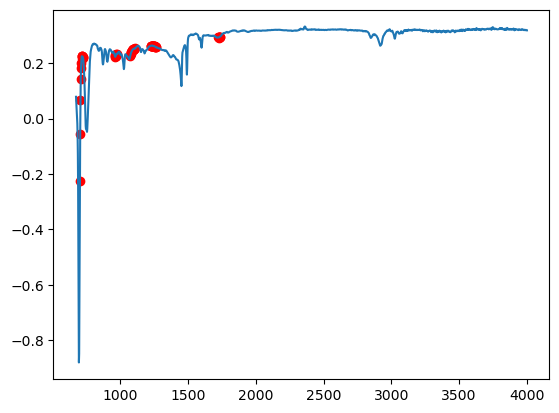

In [1498]:
#plt.plot(np.unique(df_spectra_flopp['wavelength']))
plt.scatter(wl_list.to_numpy()[(clf.coef_ > 0)[12,:]],
         np.array(X_train.loc[y_train == 'Polystyrene', (clf.coef_ > 0)[12,:]])[5], c='red')
plt.plot(wl_list.to_numpy(),
            np.array(X_train.loc[y_train == 'Polystyrene'])[5])

In [1448]:

M = ot.dist(np.array(X_train[y_train == 'Polystyrene'])[0].reshape((1725, 1)), 
            np.transpose(np.array(X_test_2[y_test_2 == 'Polyvinyl Chloride'])[0:1]), 
            'euclidean')
M /= M.max() * 0.1
        
print(ot.emd2([],[],M) )

0.13388660511817663


In [1447]:
bar_cent_list = []
for p in np.unique(y_train):
    
    n_p = sum(y_train == p)
    #bar_cent = ot.bregman.convolutional_barycenter2d(np.array(X_train[y_train == p]).reshape((n_p,1,1725)), 
    #                                  0.1, 
    #                                  np.ones(n_p) / n_p)
    #bar_cent_list.append(bar_cent)
    print(p)
    w_dist = np.zeros(n_p)
    for i in range(n_p):
        
        M = ot.dist(np.array(X_train[y_train == p])[i].reshape((1725, 1)), 
                    np.transpose(np.array(X_test_2[y_test_2 == 'Polyvinyl Chloride'])[0:1]), 'euclidean')
        M /= M.max() * 0.1
        
        w_dist[i] = ot.emd2([],[],M)
        #print(ot.emd2([],[],M) )
    print(w_dist.mean())

Acrylic
0.42422576860583877
Acrylonitrile Butadiene Styrene
0.2727509164336505
Cotton
0.7702406857479028
Nylon
0.9538291440998666
Polycarbonate
0.7460344044561283
Polyester
0.8055215769699092
Polyethylene
0.22628252094983947
Polyethylene Adipate
0.5854164604382531
Polyethylene Terephthalate
0.880405625535939
Polyethylene Vinyl Acetate
0.4722758141204175
Polylactic acid
0.781358492405722
Polypropylene
0.3102352828145521
Polystyrene
0.20862866396130436
Polyurethane
1.299623384420483
Polyvinyl Chloride
0.9596113143506858


In [1437]:
M = ot.dist(np.transpose(bar_cent), np.transpose(np.array(X_test_2[y_test_2 == p])[0:1]), 'euclidean')
M /= M.max() * 0.1
ot.emd2([],[],M) 

0.5548626050711094

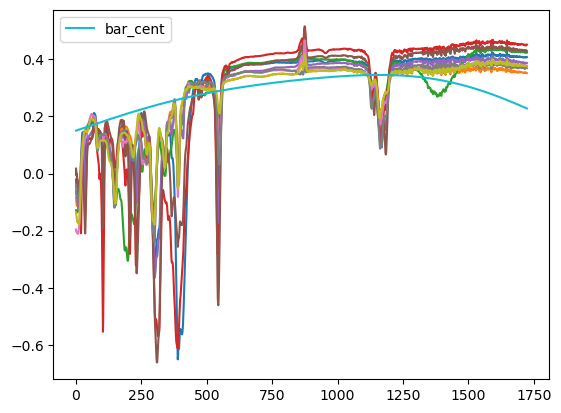

In [1514]:
for i in range(9):
    plt.plot(np.array(X_train[y_train == p])[i])
plt.plot(bar_cent[0], label='bar_cent')
plt.legend()

In [1369]:
bar_cent[0]

array([nan, nan, nan, ..., nan, nan, nan])

In [1177]:
#Xs=np.array(X_test)
#Xt=np.array(X_train)
#ys=np.array(y_test)
#yt=np.array(y_train)
#ot_emd = ot.da.EMDTransport()
#ot_emd.fit(Xs=Xs, Xt=Xt)
#transp_Xs_emd = ot_emd.transform(Xs=np.array(X_test))
#transp_Xs_emd

In [1195]:
#sns.heatmap(np.corrcoef(Xt))
#sns.heatmap(np.corrcoef(Xs))
#sns.heatmap(np.corrcoef(Xs, Xt))
#sns.heatmap(np.corrcoef(Xs, transp_Xs_emd))

In [1116]:
def corr_matching(X_ref, y_ref, X_match, r_min=0.5):
    y_ref_ = y_ref.reset_index(drop=True)
    n_ref = X_ref.shape[0]
    n_match = X_match.shape[0]
    R = np.corrcoef(X_ref, X_match)[:n_ref, n_ref:]
    return(y_ref_[R.argmax(0)], R.max(0))

y_test_hat, _ = corr_matching(X_train, y_train, transp_Xs_emd)

results_df = pd.DataFrame({'y_test':transp_ys.reset_index(drop=True), 
                           'y_test_hat':y_test_hat.reset_index(drop=True)})

(results_df['y_test'] == results_df['y_test_hat']).mean()

0.9841269841269841

In [1138]:
#from sklearn.metrics import confusion_matrix
y_test_hat, _ = corr_matching(X_train, y_train, X_test)

set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

pd.DataFrame(confusion_matrix(y_test, y_test_hat, labels=classes_test_hat))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,0,0,0,11,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,6,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,2,0,0,0,0,0,37,0,9,0,0,0,1,0,0


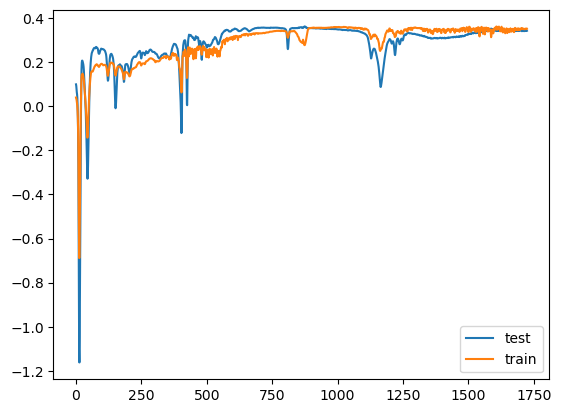

In [1197]:
plt.plot(np.array(X_test.iloc[0,]), label='test')
plt.plot(np.array(X_train.iloc[0,]), label='train')
plt.legend()

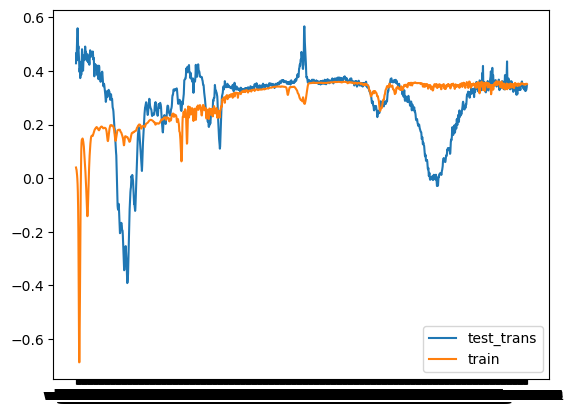

In [1200]:
plt.plot(transp_Xs_emd.iloc[0, :], label='test_trans')
plt.plot(np.array(X_train.iloc[0, :]), label='train')
plt.legend()

# Gaussian Process

In [1208]:
X, y = load_iris(return_X_y=True)
kernel = 1.0 * RBF(1.0)
gpc = GaussianProcessClassifier(random_state=0).fit(X_train, y_train)
gpc.score(X_train, y_train)
gpc.score(transp_Xs_emd, transp_ys)

1.0

0.9523809523809523

In [1242]:
gm = GaussianMixture(n_components=15, random_state=0).fit(X_train)

In [1246]:
pred = gm.predict(X_train)

In [1292]:
y_train_df = pd.DataFrame(y_train.reset_index(drop=True))
y_train_df['pred'] = pred
pred_classes = y_train_df.groupby('pred').agg(pd.Series.mode)
pred_classes.loc[4] = 'Acrylonitrile Butadiene Styrene'
y_train_df = pd.merge(pred_classes, y_train_df, on='pred') 
y_train_df
confusion_matrix(y_train_df['polymer_x'], y_train_df['polymer_y'])
#y_train_df
#pred_classes

array([[ 6,  2,  4,  0,  1,  2,  0,  0,  1,  4,  0,  1,  2,  0,  4],
       [ 0, 12,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 12,  0,  0],
       [ 0,  0, 10,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 12,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  7,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  7,  0,  0,  2,  1,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 17,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  5,  0,  0,  7,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  8,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0, 18,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 13,  0],
       [ 0,  0,  0,  0,  0,  0,  1

In [1296]:
(y_train_df['polymer_x'] ==  y_train_df['polymer_y']).mean()

0.7134502923976608